In [2]:
import pandas as pd
from pathlib import Path

# Localizar carpeta data desde la raíz o desde notebooks
carpeta = Path("data")

if not carpeta.exists():
    carpeta = Path("../data")

ruta = carpeta / "SGSST_auditorias_sinteticas_5000.csv"

df = pd.read_csv(ruta)

print("Registros:", len(df))
print("Columnas:", len(df.columns))
print("\nNombres de columnas:")
print(df.columns.tolist())

display(df.head())

Registros: 5000
Columnas: 18

Nombres de columnas:
['id_hallazgo', 'id_auditoria', 'fecha_auditoria', 'empresa', 'area', 'tipo_auditoria', 'hallazgo', 'categoria_id', 'categoria', 'criterio_evaluacion', 'clasificacion', 'nivel_riesgo', 'estado', 'responsable_area', 'fecha_cierre', 'origen_dato', 'escenario_id', 'split']


,id_hallazgo,id_auditoria,fecha_auditoria,empresa,area,tipo_auditoria,hallazgo,categoria_id,categoria,criterio_evaluacion,clasificacion,nivel_riesgo,estado,responsable_area,fecha_cierre,origen_dato,escenario_id,split
0,SST-04392,AUD-0879,2024-11-04,Empresa Andina SAS,Obras,Auditoria interna SG-SST,El equipo auditor documento la siguiente situa...,CONTRATISTAS,Gestion SST de contratistas,"Verificacion previa, coordinacion, seguimiento...",No conformidad,Alto,Abierto,Obras,NaN,SINTETICO,CONTRATISTAS-05,train
1,SST-03419,AUD-0684,2024-06-09,Constructora Atlas SAS,Talento humano,Auditoria interna SG-SST,La evidencia recopilada permite establecer que...,DOCUMENTAL,Control documental SG-SST,"Versiones, aprobaciones, trazabilidad, acceso ...",Observacion,Medio,Cerrado,Talento humano,2024-10-01,SINTETICO,DOCUMENTAL-04,test
2,SST-02966,AUD-0594,2025-12-28,Constructora Atlas SAS,Servicios generales,Auditoria interna SG-SST,Al revisar las condiciones de la planta de pro...,FORMACION,Formacion y competencias SST,"Inducciones, entrenamiento y evidencia de comp...",No conformidad,Alto,Cerrado,Servicios generales,2026-02-05,SINTETICO,FORMACION-07,train
3,SST-01228,AUD-0246,2024-06-26,Constructora Atlas SAS,Obras,Auditoria interna SG-SST,"Segun la inspeccion realizada, el pasillo de c...",LOCATIVOS,Condiciones locativas,"Orden, aseo, rutas, almacenamiento, pisos y se...",No conformidad,Alto,Abierto,Obras,NaN,SINTETICO,LOCATIVOS-06,train
4,SST-02313,AUD-0463,2024-12-13,Empresa Andina SAS,Logistica,Auditoria interna SG-SST,La muestra revisada revelo que un incidente si...,INCIDENTES,Investigacion de incidentes y accidentes,"Reporte, investigacion, causalidad y seguimien...",Observacion,Medio,Cerrado,Logistica,2025-02-15,SINTETICO,INCIDENTES-00,train


In [3]:
print("VALORES FALTANTES")
print(df.isnull().sum())

print("\nREGISTROS DUPLICADOS")
print(df.duplicated().sum())

print("\nHALLAZGOS REPETIDOS")
print(df["hallazgo"].duplicated().sum())

print("\nDISTRIBUCIÓN DE CATEGORÍAS")
print(df["categoria"].value_counts())

VALORES FALTANTES
id_hallazgo               0
id_auditoria              0
fecha_auditoria           0
empresa                   0
area                      0
tipo_auditoria            0
hallazgo                  0
categoria_id              0
categoria                 0
criterio_evaluacion       0
clasificacion             0
nivel_riesgo              0
estado                    0
responsable_area          0
fecha_cierre           2759
origen_dato               0
escenario_id              0
split                     0
dtype: int64

REGISTROS DUPLICADOS
0

HALLAZGOS REPETIDOS
1604

DISTRIBUCIÓN DE CATEGORÍAS
categoria
Formacion y competencias SST                          417
Condiciones locativas                                 417
Elementos de proteccion personal                      417
Preparacion y respuesta a emergencias                 417
Inspecciones y mantenimiento                          417
Gestion de sustancias quimicas                        417
Seguridad de maquinas y herra

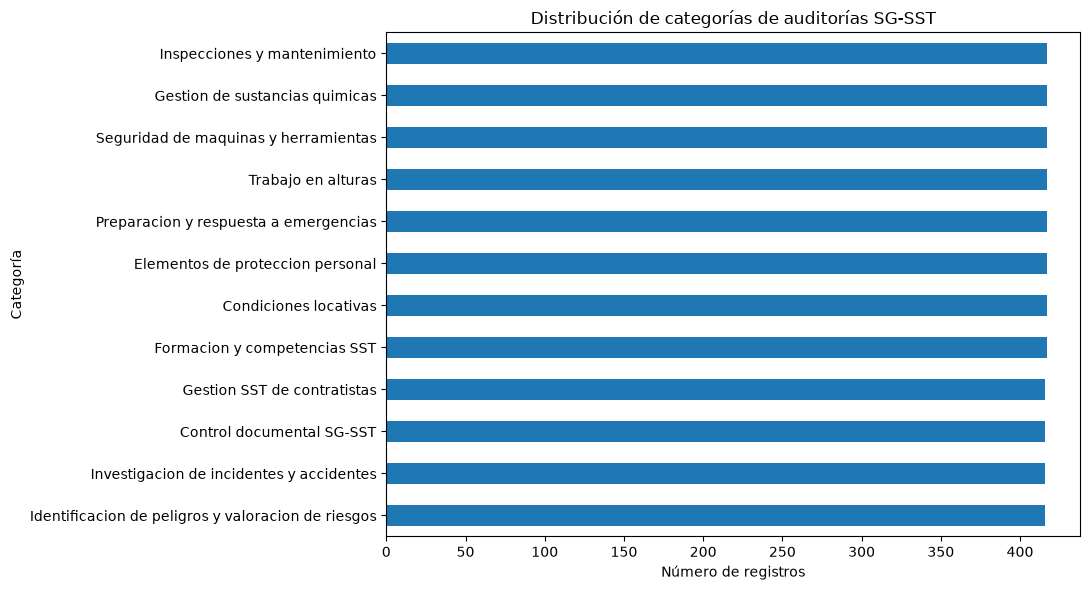

In [4]:
import matplotlib.pyplot as plt

conteo = df["categoria"].value_counts()

plt.figure(figsize=(11, 6))

conteo.sort_values().plot(kind="barh")

plt.title("Distribución de categorías de auditorías SG-SST")
plt.xlabel("Número de registros")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

In [5]:
# Distribución de registros
print("DISTRIBUCIÓN DE DATOS")
print(df["split"].value_counts())

# Comprobar los escenarios por partición
escenarios = {
    split: set(grupo["escenario_id"])
    for split, grupo in df.groupby("split")
}

print("\nESCENARIOS COMPARTIDOS")

for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    comunes = escenarios[a] & escenarios[b]
    print(f"{a} vs {b}: {len(comunes)} escenarios")

# Comprobar textos idénticos entre particiones
textos = {
    split: set(grupo["hallazgo"])
    for split, grupo in df.groupby("split")
}

print("\nTEXTOS IDÉNTICOS ENTRE PARTICIONES")

for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    comunes = textos[a] & textos[b]
    print(f"{a} vs {b}: {len(comunes)} textos")

DISTRIBUCIÓN DE DATOS
split
train    3752
test      624
val       624
Name: count, dtype: int64

ESCENARIOS COMPARTIDOS
train vs val: 0 escenarios
train vs test: 0 escenarios
val vs test: 0 escenarios

TEXTOS IDÉNTICOS ENTRE PARTICIONES
train vs val: 0 textos
train vs test: 0 textos
val vs test: 0 textos


In [6]:
# Convertir fechas
df["fecha_auditoria"] = pd.to_datetime(
    df["fecha_auditoria"]
)

df["fecha_cierre"] = pd.to_datetime(
    df["fecha_cierre"]
)

print("ESTADOS Y FECHAS DE CIERRE")

print(
    pd.crosstab(
        df["estado"],
        df["fecha_cierre"].notna()
    )
)

# Detectar cierres anteriores a la auditoría
fechas_incorrectas = df[
    df["fecha_cierre"].notna()
    & (df["fecha_cierre"] < df["fecha_auditoria"])
]

print("\nCierres anteriores a la auditoría:",
      len(fechas_incorrectas))

ESTADOS Y FECHAS DE CIERRE
fecha_cierre    False  True 
estado                      
Abierto          1153      0
Cerrado             0   2241
En seguimiento   1606      0

Cierres anteriores a la auditoría: 0


In [7]:
from itertools import combinations

# Verificar que no existan escenarios ni textos
# compartidos entre particiones.

particiones = {
    nombre: grupo
    for nombre, grupo in df.groupby("split")
}

for a, b in combinations(particiones, 2):
    escenarios_a = set(particiones[a]["escenario_id"])
    escenarios_b = set(particiones[b]["escenario_id"])

    textos_a = set(particiones[a]["hallazgo"])
    textos_b = set(particiones[b]["hallazgo"])

    assert escenarios_a.isdisjoint(escenarios_b), (
        f"Escenarios compartidos: {a} y {b}"
    )

    assert textos_a.isdisjoint(textos_b), (
        f"Textos repetidos: {a} y {b}"
    )

print("Particiones verificadas correctamente.")

Particiones verificadas correctamente.
